In [1]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
query_df = pd.read_csv("Data/query_formulation_df.csv")
serp_df = pd.read_csv("Data/logs_compiled.csv")
queries = pd.read_csv("Data/query_df.csv")

query_df.head(10)

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.3
1,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4
2,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1
3,2,g3t1,q8,Come si chiama il fiume sacro agli indiani,2026-05-19 15:14:10.201,serp8,0.4
4,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,2026-05-19 15:09:06.317,serp7,0.3
5,2,g3t2,q6,Qual è il nome del simbolo al centro della ban...,2026-05-19 15:05:41.521,serp6,0.3
6,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.3
7,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7
8,3,g3t3,q10,Quali sono 5 animali tipici dell'india,2026-05-19 14:53:41.858,serp10,0.3
9,3,g3t1,q9,come si chiama il fiume sacro agli indiani,2026-05-19 14:50:09.786,serp9,0.4


In [3]:
query_df_sample = query_df.sample(5, random_state=67).sort_index()
query_df_sample

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
3,2,g3t1,q8,Come si chiama il fiume sacro agli indiani,2026-05-19 15:14:10.201,serp8,0.4
25,5,g3t3,q28,Quali sono 5 animali tipici dell india,2026-05-19 15:08:15.219,serp28,0.3
38,8,g3t2,q50,centro bandiera india simbolo,2026-05-19 15:11:39.971,serp50,0.8
77,15,g4t1,q100,Come si chiamano i satelliti maggiori di Giove,2026-05-19 11:15:45.762,serp100,0.3
99,18,g3t3,q114,Quali sono i cinque tipici animali dell l india,2026-05-19 14:52:34.782,serp114,0.3


In [4]:
serp_df = pd.read_csv("Data/logs_compiled.csv")
serp_df.loc[serp_df["serp_id"]=="serp117"]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp
928,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://sullestradedelmondo.it/bandiera-indiana/,"Bandiera Indiana: significato, storia e curiosità","\n May 21, 2022 ... Significato dei c...",1.0,1,0,2026-05-19 15:13:43.391
929,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://mastroviaggiatore.it/saree/blog/lindia...,"L'INDIA A COLORI, I COLORI DELL'INDIA - MASTRO...","\n Feb 14, 2025 ... L'elemento più im...",2.0,1,0,2026-05-19 15:13:43.393
930,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.bandiere-nazionali.com/bandiera-in...,Bandiera di India,\n La bandiera nazionale dell'India è...,3.0,1,0,2026-05-19 15:13:43.394
931,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://liceoberchet.edu.it/ricerche/geo4d_03/...,India Britannica,\n ... dell'Ordine della stella dell'...,4.0,1,0,2026-05-19 15:13:43.396
932,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.skuola.net/geografia-medie/india-d...,"L'India: un viaggio tra cultura, geografia e t...","\n Jun 28, 2014 ... La bandiera india...",5.0,0,0,2026-05-19 15:13:43.398
933,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://it.gov-civ-guarda.pt/flag-india,"Bandiera dell'India | Storia, design e signifi...","\n Bandiera dell'India, bandiera a st...",6.0,1,1,2026-05-19 15:13:43.399
934,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.focus.it/ambiente/animali/8-cose-c...,8 cose che (forse) non sai sulle vacche sacre ...,"\n Mar 31, 2019 ... Piuttosto, vi ved...",7.0,0,0,2026-05-19 15:13:43.401
935,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://flags-world.com/it/bandiera-india-colo...,Bandiera India: colori e storia - Flags-World,"\n Jan 4, 2021 ... Successivamente, i...",8.0,1,0,2026-05-19 15:13:43.403
936,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://dinolingo.com/it/hindi-culture-hindi-c...,"Alla scoperta dell'India: cultura, geografia, ...","\n Apr 9, 2017 ... La bandiera ricord...",9.0,1,0,2026-05-19 15:13:43.404
937,18,g3t2,q117,Simbolo della bandiera dell'india,serp117,https://www.wisdomlib.org/it/concept/dharmacakra,Dharmacakra: Simbolismo e significato,"\n Apr 24, 2026 ... La ruota della le...",10.0,1,0,2026-05-19 15:13:43.406


In [5]:
relevance = pd.read_csv("Data/relevance.csv")

relevance.loc[relevance["doc"]==serp_df.iloc[932]["url"]]

,topic_number,topic,doc,relevance
30,g3t3,Animali India,https://www.skuola.net/geografia-medie/india-d...,1


In [6]:
concreteness = pd.read_excel("Resources/IT_concreteness_database.xlsx")
concreteness.head()

,Num_ANEW,ANEW,Eng_Word,Ita_Word,WordClass,Let_ITA,FreqColfis,Ln_Colfis,FreqRepub,Ln_FreqRep,N_OrtNeig,MeanFreq_Neig,N_Part_p,M_Fam,SD_Fam,M_Ima,SD_Ima,M_Con,SD_Con
0,717,1,dazzle,abbaglio,s,8,13.0,2.639057,577.0,6.359574,1.0,0.313357,20,5.50,1.905670,6.40,2.414866,4.25,2.613225
1,722,1,derelict,abbandonato,a,11,45.0,3.828641,5666.0,8.642415,4.0,11.124190,20,6.50,1.986799,6.65,1.755443,5.10,2.653697
2,624,1,abundance,abbondanza,s,10,32.0,3.496508,2257.0,7.722235,1.0,0.313357,20,5.90,1.618967,6.80,1.542384,4.75,2.022895
3,218,1,hug,abbraccio,s,9,47.0,3.871201,4902.0,8.497603,2.0,5.170395,20,7.75,1.915999,8.35,1.496487,7.70,1.750188
4,-,0,fir,abete,s,5,17.0,2.890372,732.0,6.597146,5.0,16.921293,20,7.75,1.585294,8.30,0.978721,8.05,1.316894


In [7]:
import spacy
import textstat
textstat.set_lang("it")

nlp = spacy.load("it_core_news_sm")
ITaoa = pd.read_excel("Resources/ItAoA_database.xlsx")
concreteness = pd.read_excel("Resources/IT_concreteness_database.xlsx")

query_len = []
mean_aoa = []
gulpease_index = []
fres = []
mean_conc = []

for _, row in query_df.iterrows():
    query_len.append(len(row["query"].split(" ")))
    doc = nlp(row["query"])
    aoa_vals = []
    conc_vals = []
    for token in doc:
        if token.lemma_.lower() in ITaoa["Ita_Word"].tolist():
            aoa_vals.append(ITaoa.loc[ITaoa["Ita_Word"]==token.lemma_.lower()]["M_AoA"].values[0])
        if token.lemma_.lower() in concreteness["Ita_Word"].tolist():
            conc_vals.append(concreteness.loc[concreteness["Ita_Word"]==token.lemma_.lower()]["M_Con"].values[0])
    mean_aoa.append(np.mean(aoa_vals))
    mean_conc.append(np.mean(conc_vals))
    gulpease_index.append(textstat.gulpease_index(row["query"]))
    fres.append(textstat.flesch_reading_ease(row["query"]))

query_df["query_len"] = query_len
query_df["mean_aoa"] = mean_aoa
query_df["mean_conc"] = mean_conc
query_df["gulpease_index"] = gulpease_index
query_df["fres"] = fres


c:\Users\Hrishita Chakrabarti\anaconda3\envs\SOLandChildren\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Hrishita Chakrabarti\anaconda3\envs\SOLandChildren\lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [8]:
query_df["effective_query"] = [int(p10 >= 0.8) for p10 in query_df["precision@10"]]
query_df.loc[query_df["effective_query"]==1]

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,gulpease_index,fres,effective_query
15,4,g3t1,q18,Fiume sacro indiano,2026-05-19 15:20:20.872,serp18,0.8,3,4.80,7.50,132.3,73.12,1
38,8,g3t2,q50,centro bandiera india simbolo,2026-05-19 15:11:39.971,serp50,0.8,4,5.78,7.85,99.0,61.80,1
40,8,g3t1,q52,Fiume sacro India,2026-05-19 15:16:00.828,serp52,0.8,3,4.80,7.50,139.0,93.10,1
41,8,g3t1,q53,Fiume sacro India,2026-05-19 15:16:17.475,serp53,0.8,3,4.80,7.50,139.0,93.10,1
102,18,g3t2,q117,Simbolo della bandiera dell'india,2026-05-19 15:13:42.292,serp117,0.8,4,5.78,7.85,89.0,46.80,1


In [9]:
query_df.to_csv("Data/query_formulation_df.csv", index=False, encoding="utf8")
query_df.head()

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,gulpease_index,fres,effective_query
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.3,8,3.240000,NaN,79.0,86.60,0
1,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4,4,4.800000,7.500,109.0,76.80,0
2,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1,11,5.120000,5.300,69.9,88.16,0
3,2,g3t1,q8,Come si chiama il fiume sacro agli indiani,2026-05-19 15:14:10.201,serp8,0.4,8,4.800000,7.500,82.8,101.60,0
4,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,2026-05-19 15:09:06.317,serp7,0.3,16,5.066667,6.575,59.0,83.06,0


<Axes: xlabel='effective_query', ylabel='query_len'>

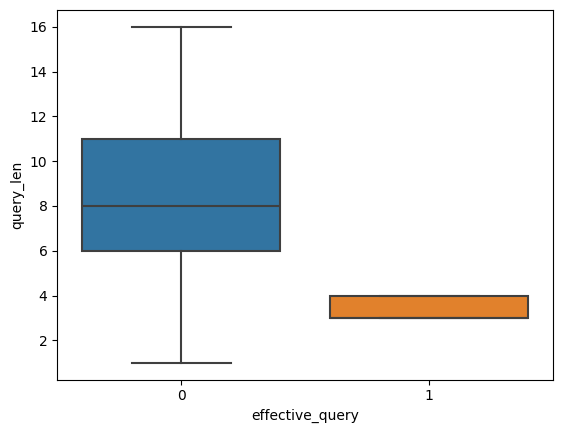

In [10]:
sns.boxplot(data=query_df, x="effective_query", y="query_len")

<Axes: xlabel='effective_query', ylabel='mean_aoa'>

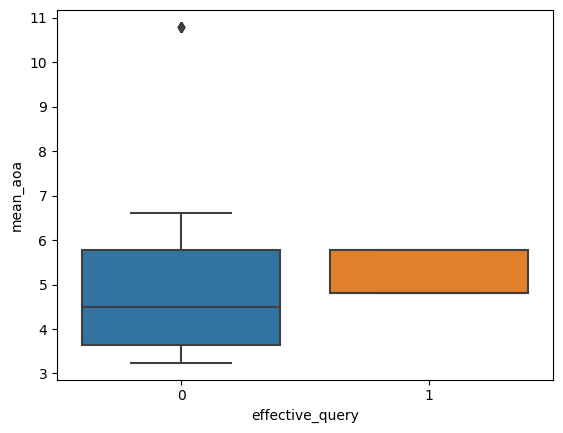

In [11]:
sns.boxplot(data=query_df, x="effective_query", y="mean_aoa")

<Axes: xlabel='effective_query', ylabel='mean_conc'>

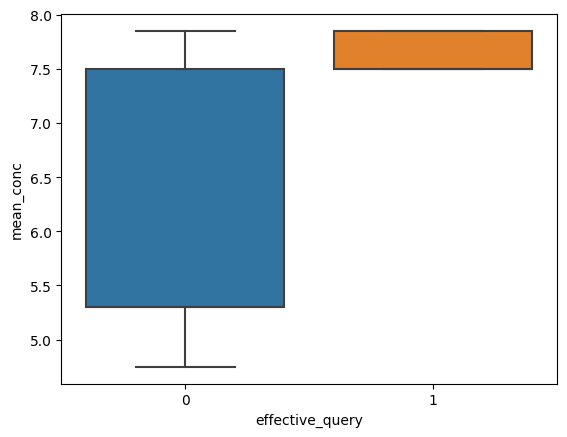

In [12]:
sns.boxplot(data=query_df, x="effective_query", y="mean_conc")

<Axes: xlabel='effective_query', ylabel='gulpease_index'>

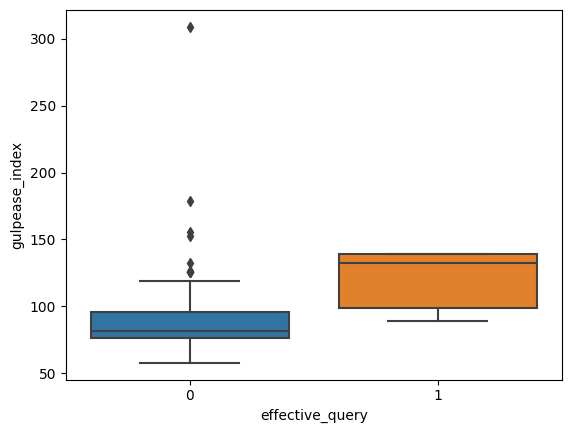

In [13]:
sns.boxplot(data=query_df, x="effective_query", y="gulpease_index")

<Axes: xlabel='effective_query', ylabel='fres'>

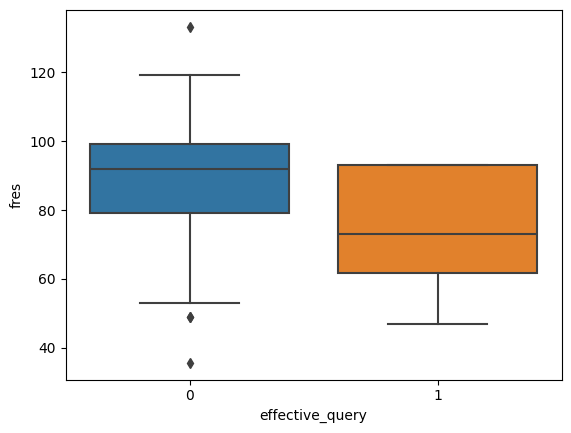

In [14]:
sns.boxplot(data=query_df, x="effective_query", y="fres")